# 01 · Data audit

**Goal of the project:** given a few seconds of a baby crying, predict what the cry is about
(hungry, tired, belly pain, ...). The labels are the 8 folders of the dataset.

Before training anything we check what the data really contains. A model can only be as
honest as its data, and this dataset has several traps:

1. augmented copies mixed in with real recordings,
2. files whose label disagrees with their filename,
3. recording-quality differences that line up with the labels,
4. many clips from the same baby.

Each section below finds one of these, and the notebook ends by saving the clean list of files
(`metadata/clean_index.csv`) that the modelling notebooks use.

In [1]:
import hashlib
import os
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from scipy.io import wavfile
from scipy.signal import welch
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

warnings.filterwarnings("ignore", category=wavfile.WavFileWarning)
pd.set_option("display.width", 140)

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(REPO / ".env")
DATA_DIR = Path(os.environ.get("BABYCRY_DATA_DIR", REPO.parent))

CLASSES = ["belly_pain", "burping", "cold_hot", "discomfort",
           "hungry", "lonely", "scared", "tired"]
# Every filename ends in a label code: "...-1.7-m-04-hu.wav" -> hungry
CODES = {"bp": "belly_pain", "bu": "burping", "ch": "cold_hot", "dc": "discomfort",
         "hu": "hungry", "lo": "lonely", "sc": "scared", "ti": "tired"}

missing = [c for c in CLASSES if not (DATA_DIR / c).is_dir()]
assert not missing, f"Class folders {missing} not found in {DATA_DIR}. Set BABYCRY_DATA_DIR in .env"
print("Dataset:", DATA_DIR)

Dataset: /Users/atanuadhikari/Desktop/Infant-State-Recognition


## 1. Index every file

Filenames follow `<uuid>-<timestamp>-<app version>-<gender>-<age>-<label code>.wav`.
The leading UUID identifies the app user who uploaded the clip, so we use it as the
**source** (in practice: one baby / one family). Some files carry an extra
`generated<k>_` prefix; we keep the original name next to it.

In [2]:
GENERATED = re.compile(r"^generated\d+_")

rows = []
for label in CLASSES:
    for path in sorted((DATA_DIR / label).glob("*.wav")):
        sr, y = wavfile.read(path)
        original = GENERATED.sub("", path.name)
        parts = original.removesuffix(".wav").split("-")
        rows.append({
            "label": label,
            "filename": path.name,
            "path": f"{label}/{path.name}",
            "generated": original != path.name,
            "original_filename": original,
            "source": original[:36].lower(),
            "filename_label": CODES.get(parts[-1]),
            "gender": parts[-3],
            "age_code": parts[-2],
            "sample_rate": sr,
            "channels": 1 if y.ndim == 1 else y.shape[1],
            "duration_s": round(len(y) / sr, 3),
            "md5": hashlib.md5(path.read_bytes()).hexdigest(),
        })
df = pd.DataFrame(rows)
print(f"{len(df)} files, all readable as PCM WAV")
df.groupby("label").size().rename("files").to_frame().T

512 files, all readable as PCM WAV


label,belly_pain,burping,cold_hot,discomfort,hungry,lonely,scared,tired
files,16,18,7,30,382,11,20,28


## 2. Generated copies

Files named `generated<k>_<original>` are augmented versions of a real clip. If a copy lands
in the test set while its original is in training, the model is graded on audio it has
effectively already heard.

In [3]:
gen = df[df["generated"]]
print(f"{len(gen)} generated files; original also in the dataset for "
      f"{gen['original_filename'].isin(df['filename']).sum()} of them\n")
pd.crosstab(df["label"], df["generated"].map({False: "real", True: "generated"}))

24 generated files; original also in the dataset for 24 of them



generated,generated,real
label,,
belly_pain,0,16
burping,9,9
cold_hot,0,7
discomfort,0,30
hungry,0,382
lonely,0,11
scared,15,5
tired,0,28


In [4]:
# What separates a copy from its original? Compare formats.
orig = df.drop_duplicates("filename").set_index("filename")   # one filename sits in two folders
pairs = gen.assign(original_sample_rate=gen["original_filename"].map(orig["sample_rate"]))
pairs.groupby(["label", "original_sample_rate", "sample_rate"]).size().rename("copies").to_frame()

copies
label   original_sample_rate sample_rate        
burping 8000                 44100             6
        44100                44100             3
scared  44100                44100            15

## 3. Files whose filename label disagrees with their folder

The label code at the end of the filename should match the folder. Where it doesn't, we can't
tell which label is right, so these files are dropped. We also look for byte-identical files.

In [5]:
mismatch = df[df["filename_label"] != df["label"]]
print(f"{len(mismatch)} files whose filename code disagrees with their folder:")
display(mismatch[["label", "filename_label", "sample_rate", "filename"]].reset_index(drop=True))

dup = df[df.duplicated("md5", keep=False)].sort_values("md5")
print(f"\nByte-identical files: {len(dup)}")
dup[["label", "filename"]]

9 files whose filename code disagrees with their folder:


,label,filename_label,sample_rate,filename
0,discomfort,cold_hot,8000,999bf14b-e417-4b44-b746-9253f81efe38-143084495...
1,discomfort,cold_hot,8000,999bf14b-e417-4b44-b746-9253f81efe38-143084497...
2,discomfort,cold_hot,8000,999bf14b-e417-4b44-b746-9253f81efe38-143084499...
3,discomfort,cold_hot,8000,999bf14b-e417-4b44-b746-9253f81efe38-143084501...
4,discomfort,cold_hot,8000,999bf14b-e417-4b44-b746-9253f81efe38-143084503...
5,discomfort,cold_hot,8000,d6cda191-4962-4308-9a36-46d5648a95ed-143108626...
6,discomfort,hungry,44100,dc5429de-26b4-48e2-bc47-bc607b9bba06-143074182...
7,discomfort,lonely,44100,dc5429de-26b4-48e2-bc47-bc607b9bba06-143074190...
8,discomfort,cold_hot,8000,f258a8e2-92cd-4843-9da4-80ed26ec8e10-143694499...



Byte-identical files: 2


,label,filename
68,discomfort,dc5429de-26b4-48e2-bc47-bc607b9bba06-143074190...
463,lonely,dc5429de-26b4-48e2-bc47-bc607b9bba06-143074190...


## 4. The clean set

Keep only real recordings whose folder and filename agree, and at most one copy of any
identical file.

In [6]:
clean = df[~df["generated"] & (df["filename_label"] == df["label"])]
clean = clean.drop_duplicates("md5").reset_index(drop=True)

summary = pd.DataFrame({
    "files": df.groupby("label").size(),
    "generated": df.groupby("label")["generated"].sum(),
    "label_mismatch": (df["filename_label"] != df["label"]).groupby(df["label"]).sum(),
    "clean_clips": clean.groupby("label").size(),
    "babies (sources)": clean.groupby("label")["source"].nunique(),
}).reindex(CLASSES).fillna(0).astype(int)
summary.loc["total"] = [len(df), df["generated"].sum(), (df["filename_label"] != df["label"]).sum(),
                        len(clean), clean["source"].nunique()]
summary

,files,generated,label_mismatch,clean_clips,babies (sources)
label,,,,,
belly_pain,16,0,0,16,7
burping,18,9,0,9,8
cold_hot,7,0,0,7,3
discomfort,30,0,9,21,14
hungry,382,0,0,382,205
lonely,11,0,0,11,8
scared,20,15,0,5,4
tired,28,0,0,28,17
total,512,24,9,479,226


## 5. File format lines up with the labels

Files are stored either as 8 kHz mono or as 44.1 kHz stereo, and the format is almost a
perfect predictor of some labels: every *hungry* and *belly_pain* clip is 8 kHz, every
*cold_hot*, *lonely* and *scared* clip is 44.1 kHz. Anything a model can pick up from the
format (sample rate, channel count, filter roll-off) is a shortcut that says nothing about the
cry.

In [7]:
sr_table = pd.crosstab(clean["label"], clean["sample_rate"]).reindex(CLASSES)
sr_table["% at 8 kHz"] = (100 * sr_table[8000] / sr_table.sum(axis=1)).round(0)
display(sr_table)
print(pd.crosstab(clean["sample_rate"], clean["channels"].map({1: "mono", 2: "stereo"})))

stereo = clean.loc[clean["channels"] == 2, "path"]
identical = sum(np.array_equal(*wavfile.read(DATA_DIR / p)[1].T) for p in stereo)
print(f"\nStereo files whose two channels are identical: {identical} / {len(stereo)}")

sample_rate,8000,44100,% at 8 kHz
label,,,
belly_pain,16,0,100.0
burping,8,1,89.0
cold_hot,0,7,0.0
discomfort,20,1,95.0
hungry,382,0,100.0
lonely,0,11,0.0
scared,0,5,0.0
tired,24,4,86.0


channels     mono  stereo
sample_rate              
8000          450       0
44100           0      29

Stereo files whose two channels are identical: 29 / 29


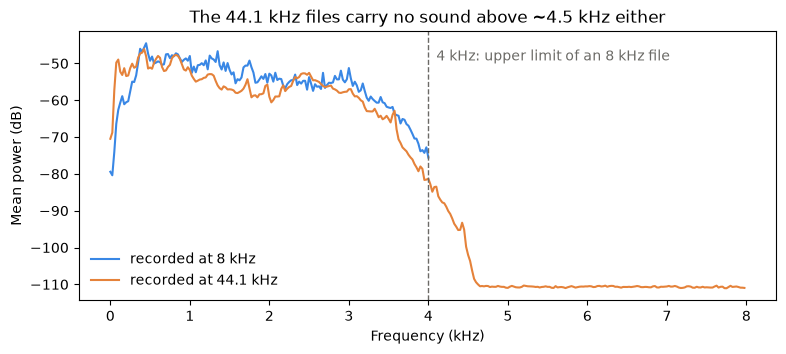

In [8]:
def mean_psd(paths, nperseg=2048):
    """Average power spectrum (dB) of the clips at their native sample rate."""
    out = []
    for p in paths:
        sr, y = wavfile.read(DATA_DIR / p)
        y = y.astype(np.float64)
        if y.ndim == 2:
            y = y.mean(axis=1)
        f, pxx = welch(y / (np.abs(y).max() + 1e-9), fs=sr, nperseg=nperseg)
        out.append(np.interp(np.arange(0, 8000, 25), f, pxx, right=np.nan))
    with warnings.catch_warnings():   # 8 kHz files have no bins above 4 kHz -> NaN columns
        warnings.simplefilter("ignore", RuntimeWarning)
        return np.arange(0, 8000, 25), 10 * np.log10(np.nanmean(out, axis=0) + 1e-12)

fig, ax = plt.subplots(figsize=(9, 3.5))
for sr, color in [(8000, "#3987e5"), (44100, "#e5823a")]:
    paths = clean.loc[clean["sample_rate"] == sr, "path"]
    f, db = mean_psd(paths.sample(min(40, len(paths)), random_state=0))
    ax.plot(f / 1000, db, color=color, label=f"recorded at {sr / 1000:g} kHz")
ax.axvline(4, color="#6b6a66", ls="--", lw=1)
ax.text(4.1, ax.get_ylim()[1] - 8, "4 kHz: upper limit of an 8 kHz file", color="#6b6a66")
ax.set(xlabel="Frequency (kHz)", ylabel="Mean power (dB)",
       title="The 44.1 kHz files carry no sound above ~4.5 kHz either")
ax.legend(frameon=False)
plt.show()

So the 44.1 kHz stereo files are phone-quality audio (the same ~4 kHz bandwidth as the 8 kHz
files) stored in a bigger container: both channels are copies of each other and there is
essentially nothing above 4.5 kHz. Converting them loses no information.

**Decision:** every clip is converted to **mono and resampled to 8 kHz** before any feature is
computed, so all clips share one format. That does not remove every difference between
recording setups: the curves above still differ in shape below ~150 Hz and just below 4 kHz
(different recording filters), and microphones, codecs and rooms differ too. Notebook 02 therefore
checks whether the original format can still be predicted from the features.

## 6. Many clips come from the same baby

If one baby's clips are split across train and test, the model can recognise the baby (or
the room, or the phone) instead of the cry type. So every split in this project is
**grouped by source**: all clips from one source go to the same side.

226 sources for 479 clips
Sources with more than one clip: 116  (largest: 15 clips)
Sources whose clips have more than one label: 31


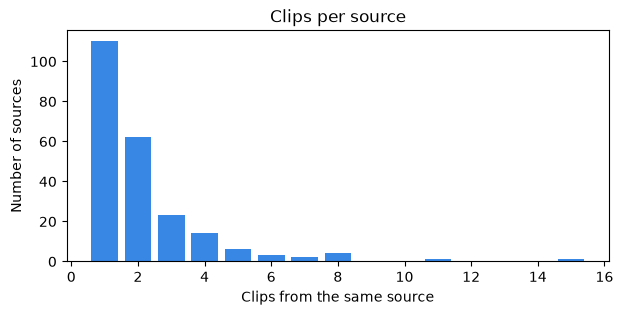

In [9]:
per_source = clean.groupby("source").agg(clips=("path", "size"), labels=("label", "nunique"))
print(f"{len(per_source)} sources for {len(clean)} clips")
print(f"Sources with more than one clip: {(per_source['clips'] > 1).sum()}  "
      f"(largest: {per_source['clips'].max()} clips)")
print(f"Sources whose clips have more than one label: {(per_source['labels'] > 1).sum()}")

fig, ax = plt.subplots(figsize=(7, 3))
counts = per_source["clips"].value_counts().sort_index()
ax.bar(counts.index, counts.values, color="#3987e5")
ax.set(xlabel="Clips from the same source", ylabel="Number of sources",
       title="Clips per source")
plt.show()

## 7. Durations and metadata

In [10]:
print(clean["duration_s"].describe().round(2).to_string())
display(pd.crosstab(clean["label"], clean["gender"]).reindex(CLASSES))
pd.crosstab(clean["label"], clean["age_code"]).reindex(CLASSES)

count    479.00
mean       6.92
std        0.11
min        6.52
25%        6.87
50%        6.94
75%        7.00
max        7.06


gender,f,m
label,,
belly_pain,1,15
burping,6,3
cold_hot,1,6
discomfort,11,10
hungry,150,232
lonely,8,3
scared,1,4
tired,14,14


age_code,04,22,26,48,72
label,,,,,
belly_pain,3,0,4,1,8
burping,1,0,4,2,2
cold_hot,4,0,3,0,0
discomfort,2,1,9,7,2
hungry,133,9,130,42,68
lonely,2,0,4,0,5
scared,3,0,0,0,2
tired,6,0,17,3,2


Clips are already about 7 s long, so the models use the full clip without trimming.
Age codes follow the Donate-a-Cry corpus naming (`04` 0–4 weeks, `48` 4–8 weeks, `26` 2–6
months, `72` 7 months–2 years, `22` over 2 years). Gender and age are parent-entered and are
**not** used as model inputs.

## 8. The baseline any model must beat

The data is dominated by one class. A "model" that always answers *hungry* already gets high
accuracy, which is why accuracy alone is misleading here. The main metrics in this project are
**balanced accuracy** (mean recall over the 8 classes) and **macro-F1**.

In [11]:
labels = list(range(len(CLASSES)))
y_true = clean["label"].map(CLASSES.index).to_numpy()
y_hungry = np.full_like(y_true, CLASSES.index("hungry"))
baseline = pd.Series({
    "accuracy": accuracy_score(y_true, y_hungry),
    "balanced accuracy": balanced_accuracy_score(y_true, y_hungry),
    "macro-F1": f1_score(y_true, y_hungry, labels=labels, average="macro", zero_division=0),
}, name="always 'hungry'").round(3)
baseline.to_frame()

,always 'hungry'
accuracy,0.797
balanced accuracy,0.125
macro-F1,0.111


## 9. Save the clean index

In [12]:
out = REPO / "metadata" / "clean_index.csv"
out.parent.mkdir(exist_ok=True)
cols = ["path", "label", "source", "sample_rate", "channels", "duration_s", "gender", "age_code"]
clean[cols].to_csv(out, index=False)
print(f"Saved {len(clean)} clips to {out.relative_to(REPO)}")

Saved 479 clips to metadata/clean_index.csv


## Summary

- **512 files -> 479 clean clips from 226 sources.**
- Removed **24 generated copies** (15 *scared*, 9 *burping*). Every copy's original is also in
  the dataset; 6 of the burping copies are 44.1 kHz versions of 8 kHz originals.
- Removed **9 *discomfort* files** whose filename says another label (one is byte-identical to
  a *lonely* clip).
- Three classes are tiny once copies are gone: *scared* 5 clips (4 sources), *cold_hot* 7 (3),
  *burping* 9 (8). Any score for these classes rests on a handful of babies and will be noisy.
- File format (8 kHz mono vs 44.1 kHz stereo) lines up with the labels. All audio is converted
  to 8 kHz mono, and notebook 02 tests for a leftover format shortcut.
- 116 sources contribute more than one clip, so **every split is grouped by source**.
- Always answering *hungry* scores **accuracy 0.797, balanced accuracy 0.125, macro-F1 0.111**.
  That's the bar to beat, and why accuracy is not the headline metric.
- Labels were entered by parents, so they are noisy and there is no known ceiling for how
  well any model can do.